Break dates: ['2021-12-13', '2021-12-20', '2022-01-04', '2022-01-19']
Break indices: [12, 19, 34, 49]

Running constant ...

Running exp_burden ...

Running rational_burden ...

Running linear_burden ...

Running power_exp_burden ...

Running power_rational_burden ...

Running gompertz_burden ...

Running mm_burden ...

Model comparison:
              model_name  success     gamma       rho             I0  \
0              mm_burden     True  0.142857  0.864811  197113.571422   
1       power_exp_burden     True  0.142857  1.086863  197113.571425   
2        gompertz_burden     True  0.142857  1.085596  197113.571453   
3          linear_burden     True  0.142857  1.085073  197113.571429   
4        rational_burden     True  0.142857  1.085126  197113.571418   
5             exp_burden     True  0.142857  1.084882  197113.571461   
6               constant     True  0.142857  1.079033  197113.571429   
7  power_rational_burden     True  0.142857  0.750883  197113.571416   

           

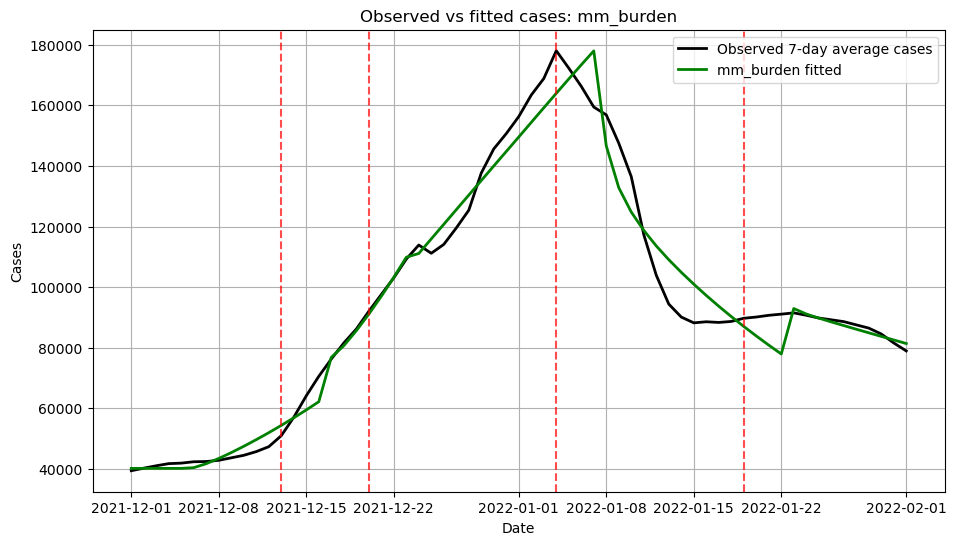

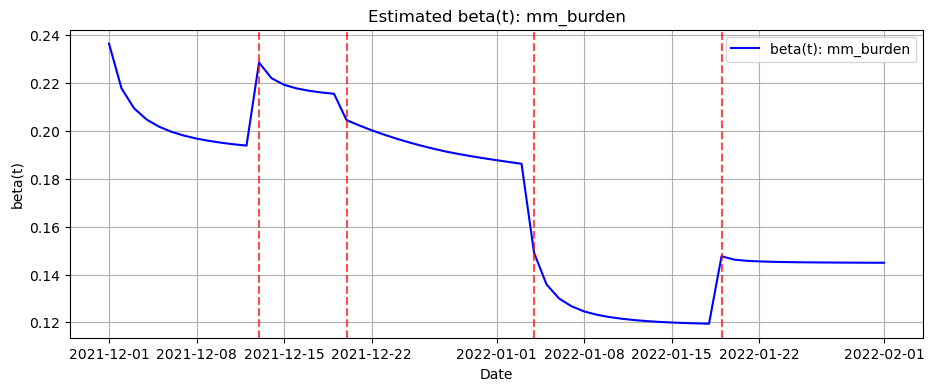

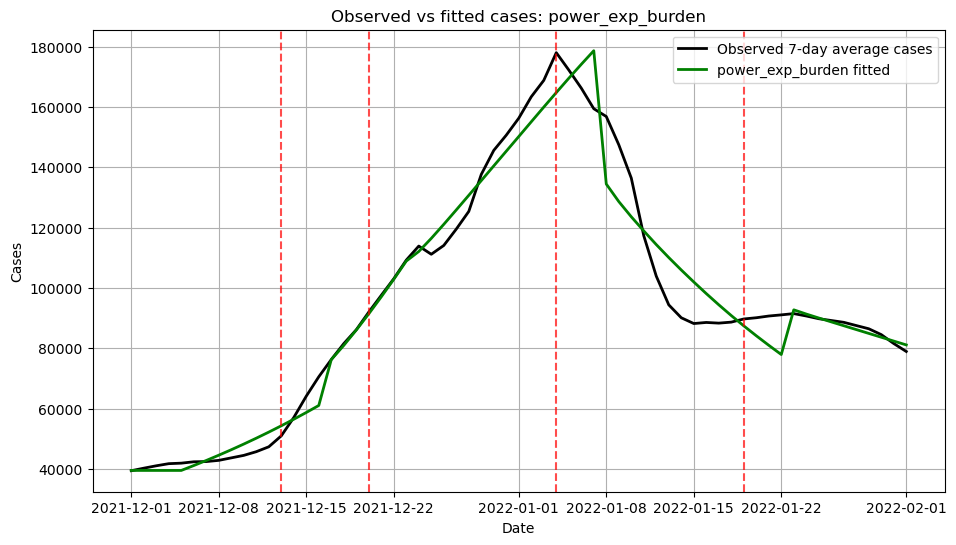

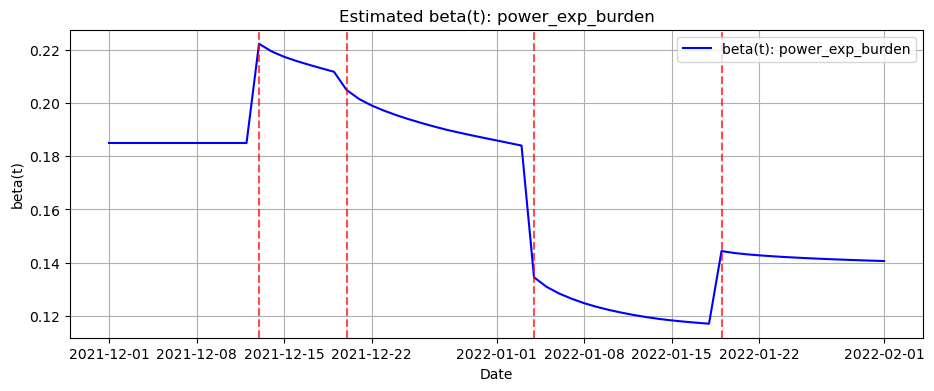

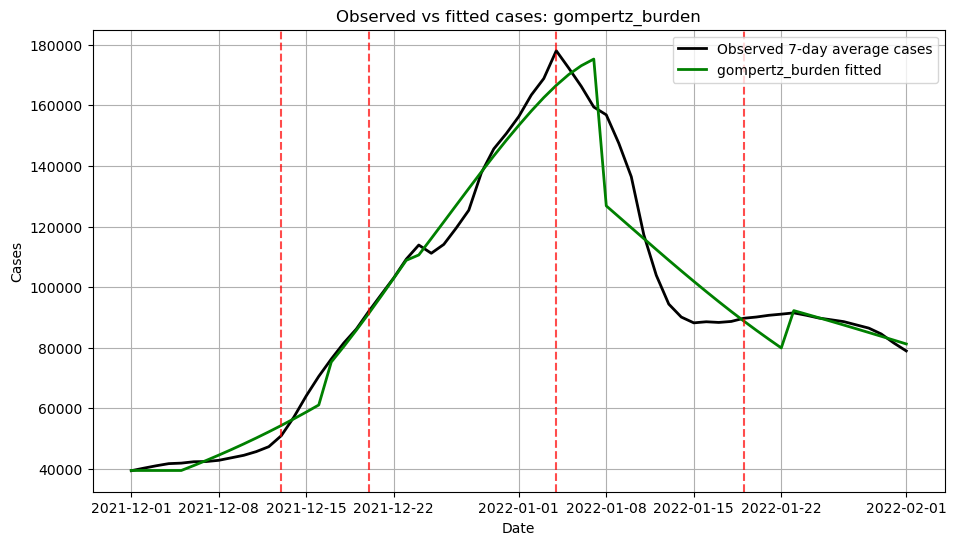

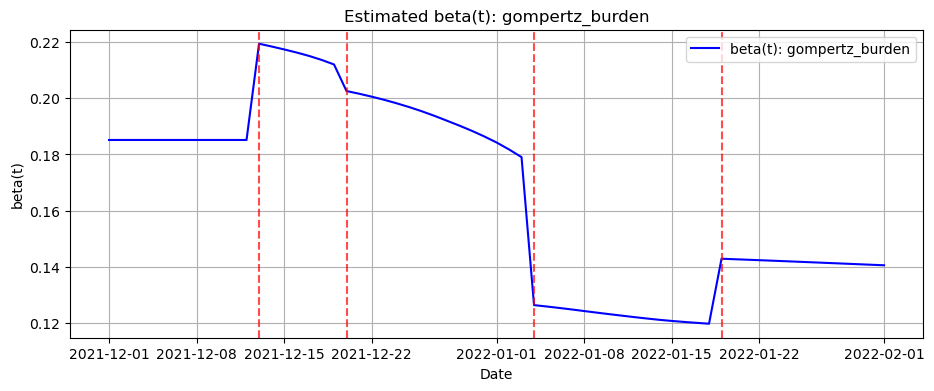

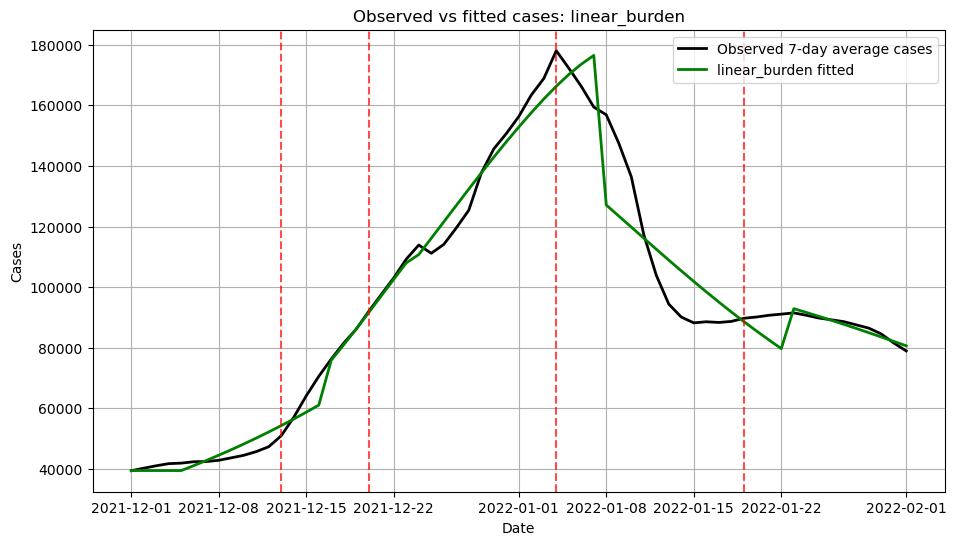

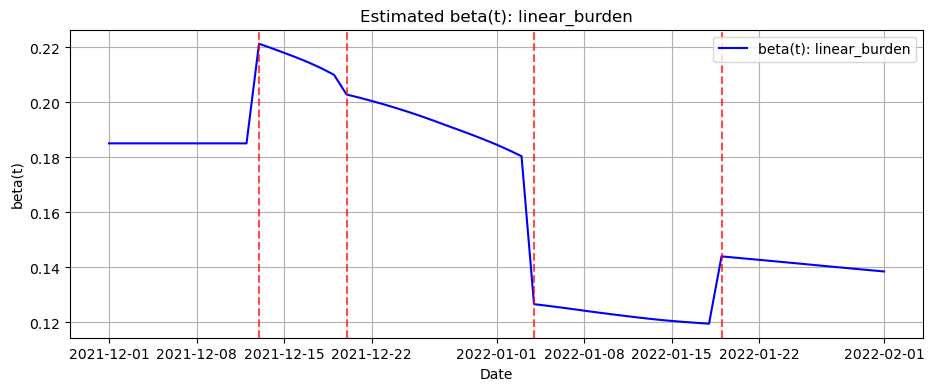

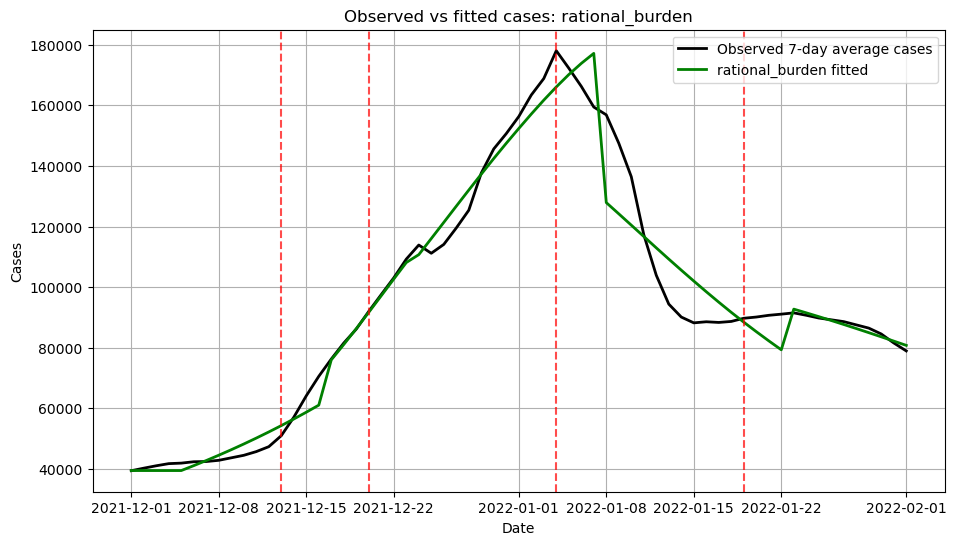

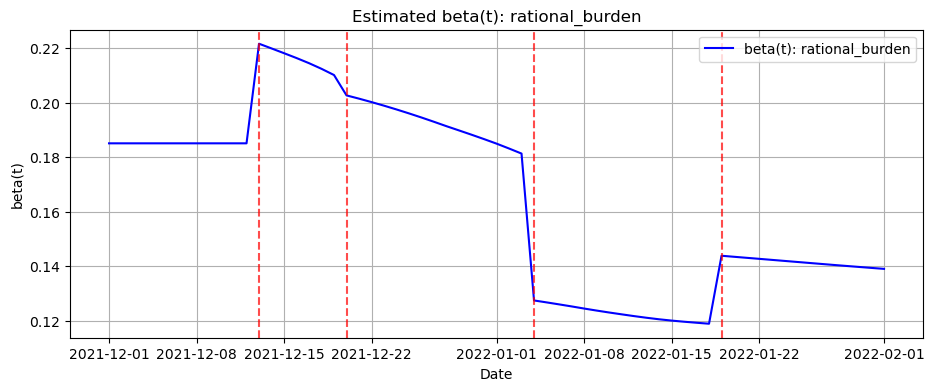

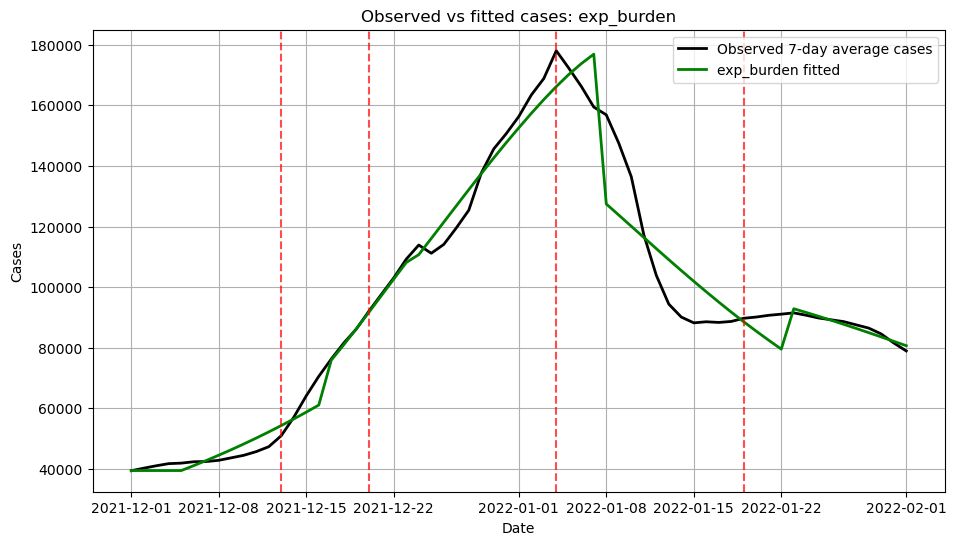

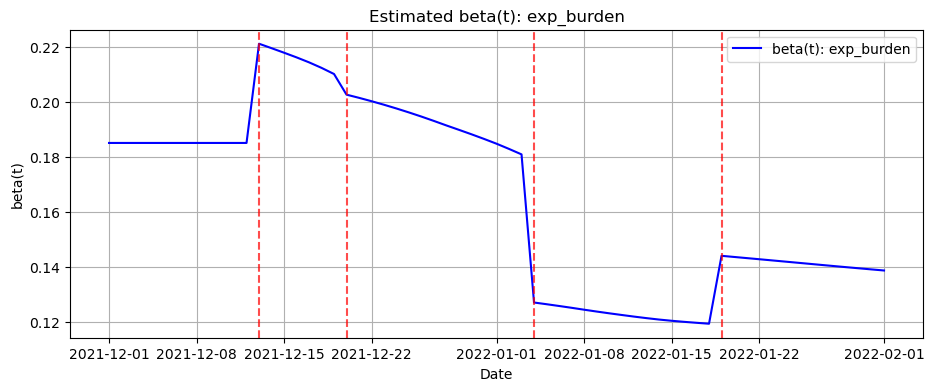


Best model: mm_burden
rho = 0.8648105231972028
I0 = 197113.57142215085
gamma = 0.14285714285714285
log_MSE = 0.00395242150535613
segment parameters:
  Segment 1: {'beta0': 0.31722566449628564, 'k': 0.6879928204974064, 'h': 0.08174357333561502}
  Segment 2: {'beta0': 0.2666330231380496, 'k': 0.25196183034098485, 'h': 0.06379502549449359}
  Segment 3: {'beta0': 0.20698006683773787, 'k': 0.18342600152341532, 'h': 0.6545019037711048}
  Segment 4: {'beta0': 0.20895084451756127, 'k': 0.8016477960560235, 'h': 0.0696602750289148}
  Segment 5: {'beta0': 0.1724001847817843, 'k': 0.1915105806369639, 'h': 0.01}


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# =========================================================
# 1. load data
# =========================================================
df = pd.read_csv("../data/uk_final.csv")
df["date"] = pd.to_datetime(df["date"])

df_fit = df[(df["date"] >= "2021-12-01") & (df["date"] <= "2022-02-01")].copy()
df_fit = df_fit.reset_index(drop=True)

dates = df_fit["date"].values
obs_cases = df_fit["cases_7d"].values.astype(float)
T = len(obs_cases)

N = 67_000_000
gamma_fixed = 1 / 7
tau_fixed = 4
eps = 1.0

# =========================================================
# 2. breakpoints
# =========================================================
break_dates = ["2021-12-13", "2021-12-20", "2022-01-04", "2022-01-19"]

for d in break_dates:
    if pd.Timestamp(d) not in set(df_fit["date"]):
        raise ValueError(f"Breakpoint {d} not found in df_fit.")

break_indices = [int(np.where(df_fit["date"] == pd.Timestamp(d))[0][0]) for d in break_dates]
n_seg = len(break_indices) + 1

print("Break dates:", break_dates)
print("Break indices:", break_indices)

# =========================================================
# 3. helpers
# =========================================================
def apply_fixed_delay(x, tau):
    tau = int(tau)
    y = np.empty_like(x)
    if tau <= 0:
        return x.copy()
    y[:tau] = x[0]
    y[tau:] = x[:-tau]
    return y

def get_segment_bounds(T, break_indices):
    bounds = [0] + break_indices + [T]
    return [(bounds[i], bounds[i + 1]) for i in range(len(bounds) - 1)]

segment_bounds = get_segment_bounds(T, break_indices)

def get_segment_index(t_idx, segment_bounds):
    for j, (a, b) in enumerate(segment_bounds):
        if a <= t_idx < b:
            return j
    return len(segment_bounds) - 1

# =========================================================
# 4. burden: cumulative delayed observed cases within segment
# =========================================================
obs_proxy = apply_fixed_delay(obs_cases, tau_fixed)

burden = np.zeros(T)
for j, (a, b) in enumerate(segment_bounds):
    seg_series = obs_proxy[a:b].copy()
    seg_cum = np.cumsum(seg_series)

    denom = np.max(seg_cum)
    if denom <= 0:
        denom = 1.0

    burden[a:b] = seg_cum / denom  # normalized to [0,1]

# =========================================================
# 5. burden-driven beta models
# =========================================================
def beta_t_value(model_name, t_idx, param_list, burden, segment_bounds):
    seg_idx = get_segment_index(t_idx, segment_bounds)
    z = burden[t_idx]
    p = param_list[seg_idx]

    if model_name == "constant":
        beta_t = p["beta0"]

    elif model_name == "exp_burden":
        beta_t = p["beta0"] * np.exp(-p["k"] * z)

    elif model_name == "rational_burden":
        beta_t = p["beta0"] / (1.0 + p["k"] * z)

    elif model_name == "linear_burden":
        beta_t = max(p["beta_min"], p["beta0"] - p["k"] * z)

    elif model_name == "power_exp_burden":
        beta_t = p["beta0"] * np.exp(-p["k"] * (z ** p["q"]))

    elif model_name == "power_rational_burden":
        beta_t = p["beta0"] / (1.0 + p["k"] * (z ** p["q"]))

    elif model_name == "gompertz_burden":
        beta_t = p["beta0"] * np.exp(-p["k"] * (np.exp(p["c"] * z) - 1.0))

    elif model_name == "mm_burden":
        # Michaelis-Menten-like saturating response
        beta_t = p["beta0"] / (1.0 + p["k"] * (z / (p["h"] + z + 1e-12)))

    else:
        raise ValueError(f"Unknown model: {model_name}")

    return max(1e-8, beta_t)

# =========================================================
# 6. parameter unpacking
# =========================================================
def unpack_theta(model_name, theta, n_seg):
    params = []
    pos = 0

    if model_name == "constant":
        for _ in range(n_seg):
            params.append({"beta0": theta[pos]})
            pos += 1

    elif model_name in ["exp_burden", "rational_burden"]:
        for _ in range(n_seg):
            params.append({
                "beta0": theta[pos],
                "k": theta[pos + 1]
            })
            pos += 2

    elif model_name == "linear_burden":
        for _ in range(n_seg):
            params.append({
                "beta0": theta[pos],
                "k": theta[pos + 1],
                "beta_min": theta[pos + 2]
            })
            pos += 3

    elif model_name in ["power_exp_burden", "power_rational_burden"]:
        for _ in range(n_seg):
            params.append({
                "beta0": theta[pos],
                "k": theta[pos + 1],
                "q": theta[pos + 2]
            })
            pos += 3

    elif model_name == "gompertz_burden":
        for _ in range(n_seg):
            params.append({
                "beta0": theta[pos],
                "k": theta[pos + 1],
                "c": theta[pos + 2]
            })
            pos += 3

    elif model_name == "mm_burden":
        for _ in range(n_seg):
            params.append({
                "beta0": theta[pos],
                "k": theta[pos + 1],
                "h": theta[pos + 2]
            })
            pos += 3

    else:
        raise ValueError(f"Unknown model: {model_name}")

    rho = theta[pos]
    I0 = theta[pos + 1]

    return params, rho, I0

def make_x0_bounds(model_name, n_seg, first_case):
    x0 = []
    bounds = []

    if model_name == "constant":
        for _ in range(n_seg):
            x0 += [0.20]
            bounds += [(1e-6, 1.0)]

    elif model_name in ["exp_burden", "rational_burden"]:
        for _ in range(n_seg):
            x0 += [0.22, 2.0]
            bounds += [(1e-6, 1.0), (0.0, 20.0)]

    elif model_name == "linear_burden":
        for _ in range(n_seg):
            x0 += [0.22, 0.15, 0.03]
            bounds += [(1e-6, 1.0), (0.0, 1.0), (1e-6, 0.5)]

    elif model_name in ["power_exp_burden", "power_rational_burden"]:
        for _ in range(n_seg):
            x0 += [0.22, 2.0, 1.5]   # beta0, k, q
            bounds += [(1e-6, 1.0), (0.0, 30.0), (0.3, 5.0)]

    elif model_name == "gompertz_burden":
        for _ in range(n_seg):
            x0 += [0.22, 1.0, 3.0]   # beta0, k, c
            bounds += [(1e-6, 1.0), (0.0, 20.0), (0.1, 10.0)]

    elif model_name == "mm_burden":
        for _ in range(n_seg):
            x0 += [0.22, 2.0, 0.3]   # beta0, k, h
            bounds += [(1e-6, 1.0), (0.0, 30.0), (0.01, 2.0)]

    else:
        raise ValueError(f"Unknown model: {model_name}")

    x0 += [1.0, first_case * 5.0]  # rho, I0
    bounds += [(1e-6, 100.0), (1.0, 5_000_000.0)]

    return np.array(x0, dtype=float), bounds

# =========================================================
# 7. discrete-time SIR
# =========================================================
def simulate_discrete_sir(model_name, theta, burden, gamma, N, T, tau, segment_bounds):
    params, rho, I0 = unpack_theta(model_name, theta, n_seg)

    if rho <= 0 or I0 <= 0 or I0 >= N:
        raise ValueError("Invalid rho or I0")

    S = np.zeros(T)
    I = np.zeros(T)
    R = np.zeros(T)
    beta_path = np.zeros(T)
    incidence = np.zeros(T)

    S[0] = N - I0
    I[0] = I0
    R[0] = 0.0

    for t in range(T):
        beta_path[t] = beta_t_value(model_name, t, params, burden, segment_bounds)
        incidence[t] = beta_path[t] * S[t] * I[t] / N

        if t < T - 1:
            new_inf = incidence[t]
            new_rec = gamma * I[t]

            S[t + 1] = max(0.0, S[t] - new_inf)
            I[t + 1] = max(0.0, I[t] + new_inf - new_rec)
            R[t + 1] = max(0.0, R[t] + new_rec)

    fitted_cases = rho * apply_fixed_delay(incidence, tau)

    return {
        "S": S,
        "I": I,
        "R": R,
        "beta_path": beta_path,
        "incidence": incidence,
        "fitted_cases": fitted_cases,
        "rho": rho,
        "I0": I0,
        "params": params,
    }

# =========================================================
# 8. regularization
# =========================================================
def regularization_penalty(theta, lam=1e-4):
    return lam * np.sum(theta[:-2] ** 2)

# =========================================================
# 9. loss
# =========================================================
def loss_fn(theta, model_name):
    try:
        sim = simulate_discrete_sir(
            model_name=model_name,
            theta=theta,
            burden=burden,
            gamma=gamma_fixed,
            N=N,
            T=T,
            tau=tau_fixed,
            segment_bounds=segment_bounds
        )

        fitted = sim["fitted_cases"]

        if np.any(np.isnan(fitted)) or np.any(np.isinf(fitted)):
            return 1e20
        if np.any(fitted < 0):
            return 1e20

        fit_loss = np.mean((np.log(fitted + eps) - np.log(obs_cases + eps)) ** 2)
        reg = regularization_penalty(theta, lam=1e-4)
        return fit_loss + reg

    except Exception:
        return 1e20

# =========================================================
# 10. fit models
# =========================================================
candidate_models = [
    "constant",
    "exp_burden",
    "rational_burden",
    "linear_burden",
    "power_exp_burden",
    "power_rational_burden",
    "gompertz_burden",
    "mm_burden",
]

all_results = []

for model_name in candidate_models:
    print(f"\nRunning {model_name} ...")

    x0, bounds = make_x0_bounds(model_name, n_seg, obs_cases[0])

    result = minimize(
        loss_fn,
        x0=x0,
        args=(model_name,),
        method="L-BFGS-B",
        bounds=bounds,
    )

    theta_hat = result.x

    sim = simulate_discrete_sir(
        model_name=model_name,
        theta=theta_hat,
        burden=burden,
        gamma=gamma_fixed,
        N=N,
        T=T,
        tau=tau_fixed,
        segment_bounds=segment_bounds
    )

    fitted = sim["fitted_cases"]
    mse = np.mean((fitted - obs_cases) ** 2)
    rmse = np.sqrt(mse)
    log_mse = np.mean((np.log(fitted + eps) - np.log(obs_cases + eps)) ** 2)

    all_results.append({
        "model_name": model_name,
        "success": result.success,
        "message": result.message,
        "theta_hat": theta_hat,
        "params": sim["params"],
        "rho": sim["rho"],
        "I0": sim["I0"],
        "gamma": gamma_fixed,
        "MSE": mse,
        "RMSE": rmse,
        "log_MSE": log_mse,
        "fitted_cases": fitted,
        "beta_path": sim["beta_path"],
        "I_path": sim["I"],
        "incidence": sim["incidence"],
    })

# =========================================================
# 11. summary
# =========================================================
rows = []
for r in all_results:
    row = {
        "model_name": r["model_name"],
        "success": r["success"],
        "gamma": r["gamma"],
        "rho": r["rho"],
        "I0": r["I0"],
        "MSE": r["MSE"],
        "RMSE": r["RMSE"],
        "log_MSE": r["log_MSE"],
    }

    for j, p in enumerate(r["params"], start=1):
        for k, v in p.items():
            row[f"seg{j}_{k}"] = v

    rows.append(row)

results_df = pd.DataFrame(rows).sort_values("log_MSE").reset_index(drop=True)
print("\nModel comparison:")
print(results_df)
results_df.to_csv("../results/burden_expression_comparison.csv", index=False)

# =========================================================
# 12. plots
# =========================================================
top_k = min(6, len(all_results))
top_names = results_df.head(top_k)["model_name"].tolist()
lookup = {r["model_name"]: r for r in all_results}

for name in top_names:
    r = lookup[name]

    plt.figure(figsize=(11, 6))
    plt.plot(df_fit["date"], obs_cases, label="Observed 7-day average cases", linewidth=2, color="black")
    plt.plot(df_fit["date"], r["fitted_cases"], label=f"{name} fitted", linewidth=2, color="green")
    for d in break_dates:
        plt.axvline(pd.Timestamp(d), color="red", linestyle="--", alpha=0.7)
    plt.title(f"Observed vs fitted cases: {name}")
    plt.xlabel("Date")
    plt.ylabel("Cases")
    plt.legend()
    plt.grid()
    plt.show()

    plt.figure(figsize=(11, 4))
    plt.plot(df_fit["date"], r["beta_path"], label=f"beta(t): {name}", color="blue")
    for d in break_dates:
        plt.axvline(pd.Timestamp(d), color="red", linestyle="--", alpha=0.7)
    plt.title(f"Estimated beta(t): {name}")
    plt.xlabel("Date")
    plt.ylabel("beta(t)")
    plt.legend()
    plt.grid()
    plt.show()

# =========================================================
# 13. best model
# =========================================================
best_name = results_df.iloc[0]["model_name"]
best = lookup[best_name]

print("\nBest model:", best_name)
print("rho =", best["rho"])
print("I0 =", best["I0"])
print("gamma =", best["gamma"])
print("log_MSE =", best["log_MSE"])
print("segment parameters:")
for j, p in enumerate(best["params"], start=1):
    print(f"  Segment {j}: {p}")

In [3]:
candidate_mid_dates = [
    "2022-01-02",
    "2022-01-04",
    "2022-01-06",
    "2022-01-08",
    "2022-01-10",
]

results_bp = []

for mid_date in candidate_mid_dates:

    print(f"\nTesting breakpoint: {mid_date}")

    break_dates = [
        "2021-12-13",
        "2021-12-20",
        mid_date,
        "2022-01-19",
    ]

    # convert to indices
    break_indices = [
        int(np.where(df_fit["date"] == pd.Timestamp(d))[0][0])
        for d in break_dates
    ]

    segment_bounds = get_segment_bounds(T, break_indices)
    n_seg = len(segment_bounds)

    # rebuild burden
    burden = np.zeros(T)
    for j, (a, b) in enumerate(segment_bounds):
        seg_series = obs_proxy[a:b].copy()
        seg_cum = np.cumsum(seg_series)
        denom = np.max(seg_cum)
        if denom <= 0:
            denom = 1.0
        burden[a:b] = seg_cum / denom

    # initial guess
    x0, bounds = make_x0_bounds("mm_burden", n_seg, obs_cases[0])

    # fit
    result = minimize(
        loss_fn,
        x0=x0,
        args=("mm_burden",),
        method="L-BFGS-B",
        bounds=bounds,
    )

    theta_hat = result.x

    sim = simulate_discrete_sir(
        model_name="mm_burden",
        theta=theta_hat,
        burden=burden,
        gamma=gamma_fixed,
        N=N,
        T=T,
        tau=tau_fixed,
        segment_bounds=segment_bounds
    )

    fitted = sim["fitted_cases"]

    log_mse = np.mean((np.log(fitted + eps) - np.log(obs_cases + eps)) ** 2)

    results_bp.append({
        "mid_date": mid_date,
        "log_MSE": log_mse,
    })

# 转表
bp_df = pd.DataFrame(results_bp).sort_values("log_MSE")
print("\nBreakpoint comparison:")
print(bp_df)


Testing breakpoint: 2022-01-02

Testing breakpoint: 2022-01-04

Testing breakpoint: 2022-01-06

Testing breakpoint: 2022-01-08

Testing breakpoint: 2022-01-10

Breakpoint comparison:
     mid_date   log_MSE
0  2022-01-02  0.003821
1  2022-01-04  0.003952
2  2022-01-06  0.004176
3  2022-01-08  0.005424
4  2022-01-10  0.007563
